# Wall Street Quants Project - Statistical Arbitrage in Cryptocurrencies

In [10]:
# Importing modules

import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS

In [11]:
# Defining the training and testing periods
# Training ~ Jan 2020 to June 2025
# Testing ~ July 2025 to June 2026

TRAIN_START = "2020-01-01"
TRAIN_END = "2025-06-30"

TEST_START = "2025-07-01"
TEST_END = "2026-06-30"

TRAIN = pd.date_range(start=TRAIN_START, end=TRAIN_END)
TEST = pd.date_range(start=TEST_START, end=TEST_END)

In [12]:
# 20-cryptocurrency universe from coinbase
# Clean, liquid, non-stablecoin assets with history of at least 6 years
# Sufficiently large market cap and daily volumes

# LIMITATION
# Coins are selected by information available today
# rather than information available at the time of back-test

# Removed SHIB-USD since it has inf value
ticker_universe = ["BTC-USD", "ETH-USD", "BNB-USD", "XRP-USD", "SOL-USD", "TRX-USD", "ZEC-USD", "DOGE-USD", "XMR-USD", "LINK-USD", "ADA-USD", "XLM-USD", "BCH-USD", "LTC-USD", "NEAR-USD", "AVAX-USD", "HBAR-USD", "KCS-USD", "ALGO-USD", "DASH-USD"]

In [13]:
# Downloading ticker prices using yfinance API
daily_prices = yf.download(tickers=ticker_universe, period="max", interval="1d")

[*********************100%***********************]  20 of 20 completed


In [14]:
# Calculating daily returns and volumes for each coin

daily_returns = daily_prices["Close"].pct_change(fill_method=None)
daily_volumes = daily_prices["Volume"]

In [60]:
# Calculating annualised Sharpe ratio from returns 
def sharpeRatio(returns):
    return returns.mean() / returns.std() * np.sqrt(252)

# Calculating rolling z-score
def zScore(x, window=90):
    return (x - x.rolling(window).mean()) / x.rolling(window).std()

# Calculating t-stat
def tStat(x):
    return (x - x.mean()) / (x.std() / np.sqrt(len(x)))

In [16]:
# Holding period
weight_lag = 5

# Regression window for linear regression
rolling_regression_window = 360

In [77]:
# Creating the feature matrix of predictor variables
# that will go into the OLS regression model

def featureX(ticker="BTC-USD"):

    df = pd.DataFrame()

    # 3 time horizons have found to provide the most alpha
    # 7-day horizon, 28-day horizon, and 60-day horizon
    # Time horizon referred to as n below
    time_horizons = [7, 28, 60]

    for time_horizon in time_horizons:

        # Rolling returns average over the last n days
        df[f"{time_horizon:02d}_AVG"] = daily_returns.shift().rolling(time_horizon).mean()[ticker]

        # Ratio of yesterday's volume to average volume over the last n days
        df[f"{time_horizon:02d}_VOL_RATIO"] = (daily_volumes.shift() / daily_volumes.shift().rolling(time_horizon).mean())[ticker]

        # Product of the above two features -> indicative of momentum over last n days
        df[f"{time_horizon:02d}_MOM"] = daily_returns.shift().rolling(time_horizon).mean()[ticker] * (daily_volumes.shift() / daily_volumes.shift().rolling(time_horizon).mean())[ticker]

        # Rolling returns volatility over the last n days
        df[f"{time_horizon:02d}_STD"] = daily_returns.shift().rolling(time_horizon).std()[ticker]

        # Reciprocal of the above feature
        df[f"INV_{time_horizon:02d}_STD"] = 1 / daily_returns.shift().rolling(time_horizon).std()[ticker]

        # Sharpe ratio over the last n days
        df[f"{time_horizon:02d}_SHARPE"] = daily_returns.shift().rolling(time_horizon).mean()[ticker] / daily_returns.shift().rolling(time_horizon).std()[ticker]

    # Z-score of rolling average of BTC-USD returns over last 28 days for over the last 90 days
    # Not done for BTC-USD itself
    # if ticker != "BTC-USD":
    #         df[f"BTC_USD"] = (daily_returns["BTC-USD"].shift().rolling(28).mean() - daily_returns["BTC-USD"].shift().rolling(90).mean()) / daily_returns["BTC-USD"].shift().rolling(90).std()

    return df

# Example of X feature matrix for BTC-USD
# for demonstrative and debugging purposes
feature_x = featureX()
feature_x.dropna()

,07_AVG,07_VOL_RATIO,07_MOM,07_STD,INV_07_STD,07_SHARPE,28_AVG,28_VOL_RATIO,28_MOM,28_STD,INV_28_STD,28_SHARPE,60_AVG,60_VOL_RATIO,60_MOM,60_STD,INV_60_STD,60_SHARPE
Date,,,,,,,,,,,,,,,,,,
2014-11-17,0.011385,0.400208,0.004557,0.069811,14.324402,0.163089,0.000668,0.610767,0.000408,0.041984,23.818571,0.015919,-0.001977,0.434740,-0.000859,0.039705,25.185563,-0.049790
2014-11-18,0.009771,1.325220,0.012949,0.069977,14.290478,0.139639,0.001239,2.036304,0.002523,0.041840,23.900291,0.029614,-0.000799,1.509621,-0.001205,0.038629,25.887473,-0.020672
2014-11-19,0.004969,0.957002,0.004755,0.071723,13.942590,0.069279,-0.000225,1.531972,-0.000345,0.042257,23.664899,-0.005329,-0.000160,1.175667,-0.000188,0.037775,26.472458,-0.004229
2014-11-20,-0.014697,0.634564,-0.009326,0.033280,30.048494,-0.441610,0.000591,0.889079,0.000526,0.042310,23.635057,0.013975,-0.000517,0.698359,-0.000361,0.037530,26.645132,-0.013786
2014-11-21,-0.022270,1.008587,-0.022462,0.036976,27.044219,-0.602286,0.000766,1.187443,0.000909,0.042041,23.786446,0.018211,-0.001101,0.931577,-0.001026,0.038179,26.192343,-0.028844
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-15,-0.002846,1.254044,-0.003569,0.016641,60.092034,-0.171043,0.002658,1.103118,0.002932,0.020753,48.185646,0.128078,0.004568,1.073037,0.004902,0.023343,42.839534,0.195699
2026-10-16,0.000912,1.610034,0.001468,0.015242,65.608803,0.059820,0.002793,1.352157,0.003776,0.020770,48.146823,0.134458,0.004741,1.323088,0.006273,0.023322,42.877375,0.203276
2026-10-17,-0.001724,1.008422,-0.001739,0.014868,67.260397,-0.115963,0.000412,0.870316,0.000358,0.017698,56.505034,0.023263,0.004163,0.835888,0.003480,0.023194,43.114633,0.179492


In [78]:
# Creating the feature vector of dependent variables
# that will go into the OLS regression model
def featureY(ticker="BTC-USD"):
    return daily_returns[ticker][::-1].rolling(window=weight_lag).sum()[::-1]

# Example of Y feature vector for BTC-USD
# for demonstrative and debugging purposes
feature_y = featureY()
feature_y.dropna()

Date
2014-09-18   -0.122340
2014-09-19    0.033233
2014-09-20    0.074195
2014-09-21    0.010977
2014-09-22    0.018266
                ...   
2026-10-11   -0.008702
2026-10-12   -0.025755
2026-10-13   -0.004303
2026-10-14   -0.012793
2026-10-15    0.013880
Freq: D, Name: BTC-USD, Length: 4411, dtype: float64

In [79]:
# Performing rolling OLS to estimate mean returns of each ticker over the following weight_lag days (featureY) using historical predictor data (featureX)

# Note: rolling_regression_window controls for the lookback window for which the rollingOLS is performed
def Regression(ticker="BTC-USD"):
    X = featureX(ticker).dropna()
    Y = featureY(ticker).dropna()

    # X and Y may not have the same index
    # taking the intersection of their indices allows
    # the rolling OLS model to work properly
    common_index = X.index.intersection(Y.index)
    regression_model = RollingOLS(Y.loc[common_index], sm.add_constant(X.loc[common_index]), window=rolling_regression_window).fit()
    return regression_model

# Each ticker gets assigned a dataframe of coefficients for each column in featureX - this is used to predict returns for unseen information
regression_parameters = {
    ticker: Regression(ticker).params.shift(weight_lag).dropna() for ticker in ticker_universe
}

In [80]:
# Constructing the weighted stat-arb portfolio for the momentum strategy
def momentumWeights():

    # Creating the signal for each ticker using rolling OLS coefficients
    signal = pd.DataFrame({
        ticker: (sm.add_constant(featureX(ticker)) * regression_parameters[ticker]).sum(axis=1) for ticker in ticker_universe
    })

    # Converting signal into portfolio weights using rank-demean-normalise method
    # Note: Portfolio are weights are lagged to indicate holding period defined by weight_lag
    ranked = (-signal).rank(axis=1)
    demeaned =  ranked.sub(ranked.mean(axis=1), axis=0)
    weights = demeaned.div(demeaned.abs().sum(axis=1), axis=0)
    lagged_weights = weights.iloc[::weight_lag].reindex(weights.index, method="ffill")
    return lagged_weights

momentum_weights = momentumWeights()
momentum_weights.dropna().loc[TRAIN]

,BTC-USD,ETH-USD,BNB-USD,XRP-USD,SOL-USD,TRX-USD,ZEC-USD,DOGE-USD,XMR-USD,LINK-USD,ADA-USD,XLM-USD,BCH-USD,LTC-USD,NEAR-USD,AVAX-USD,HBAR-USD,KCS-USD,ALGO-USD,DASH-USD
2020-01-01,0.025,0.055,0.095,-0.075,-0.045,-0.005,0.015,-0.015,0.005,-0.085,0.035,-0.095,0.075,0.045,-0.045,-0.045,-0.045,0.065,-0.045,0.085
2020-01-02,0.025,0.055,0.095,-0.075,-0.045,-0.005,0.015,-0.015,0.005,-0.085,0.035,-0.095,0.075,0.045,-0.045,-0.045,-0.045,0.065,-0.045,0.085
2020-01-03,0.025,0.055,0.095,-0.075,-0.045,-0.005,0.015,-0.015,0.005,-0.085,0.035,-0.095,0.075,0.045,-0.045,-0.045,-0.045,0.065,-0.045,0.085
2020-01-04,-0.005,0.035,0.085,-0.015,-0.045,0.015,0.005,0.025,0.075,-0.075,0.095,-0.095,0.045,0.065,-0.045,-0.045,-0.045,-0.085,-0.045,0.055
2020-01-05,-0.005,0.035,0.085,-0.015,-0.045,0.015,0.005,0.025,0.075,-0.075,0.095,-0.095,0.045,0.065,-0.045,-0.045,-0.045,-0.085,-0.045,0.055
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-26,0.065,0.055,0.005,-0.055,-0.085,-0.025,-0.065,-0.005,0.085,-0.035,-0.095,0.075,-0.075,-0.045,0.045,0.015,0.025,0.095,-0.015,0.035
2025-06-27,0.065,0.055,0.005,-0.055,-0.085,-0.025,-0.065,-0.005,0.085,-0.035,-0.095,0.075,-0.075,-0.045,0.045,0.015,0.025,0.095,-0.015,0.035
2025-06-28,0.065,0.055,0.005,-0.055,-0.085,-0.025,-0.065,-0.005,0.085,-0.035,-0.095,0.075,-0.075,-0.045,0.045,0.015,0.025,0.095,-0.015,0.035
2025-06-29,0.065,0.055,0.005,-0.055,-0.085,-0.025,-0.065,-0.005,0.085,-0.035,-0.095,0.075,-0.075,-0.045,0.045,0.015,0.025,0.095,-0.015,0.035


In [81]:
# Gross returns of momentum strategy
def grossMomentum(momentum_weights):
    return (momentum_weights * daily_returns).sum(axis=1)

# Net returns of momentum strategy (transaction costs included)
# Note: Total 20bps execution cost ~ 7bps commission cost + 13bps slippage cost
def netMomentum(momentum_weights):
    return (momentum_weights * daily_returns).subtract((momentum_weights - momentum_weights.shift()).abs() * 0.002, fill_value=0).sum(axis=1)

# Gross and net returns for the training and test set

train_gross_momentum = grossMomentum(momentum_weights)[TRAIN]
train_net_momentum = netMomentum(momentum_weights)[TRAIN]

test_gross_momentum = grossMomentum(momentum_weights)[TEST]
test_net_momentum = netMomentum(momentum_weights)[TEST]

In [82]:
def turnover(momentum_weights):
    return ((momentum_weights - momentum_weights.shift()).abs() * 0.002).sum(axis=1)

train_turnover = turnover(momentum_weights)[TRAIN]
test_turnover = turnover(momentum_weights)[TEST]

In [83]:
def drawdown(returns):
    return (1 + returns).cumprod() / (1 + returns).cumprod().cummax() - 1

train_drawdown = drawdown(train_net_momentum)
test_drawdown = drawdown(test_net_momentum)

In [84]:
def alpha(returns, ticker="BTC-USD"):
    X = daily_returns[ticker].dropna()
    Y = returns.dropna()
    common_index = X.index.intersection(Y.index)
    regression_model = sm.OLS(Y.loc[common_index], sm.add_constant(X[common_index])).fit()
    return {
        "alpha": regression_model.params["const"],
        "t-stat": regression_model.tvalues["const"]
    }

train_alpha = alpha(train_net_momentum)
test_alpha = alpha(test_net_momentum)

## Training Sample Results

In [85]:
print(f"""
Training Sample:
Gross Sharpe Ratio: {sharpeRatio(train_gross_momentum):.2f}
Net Sharpe Ratio: {sharpeRatio(train_net_momentum):.2f}
""")


Training Sample:
Gross Sharpe Ratio: 1.37
Net Sharpe Ratio: 1.00



<Axes: title={'center': 'Train Momentum Strategy Sharpe (Overall 1.00)'}, ylabel='Net Sharpe Ratio'>

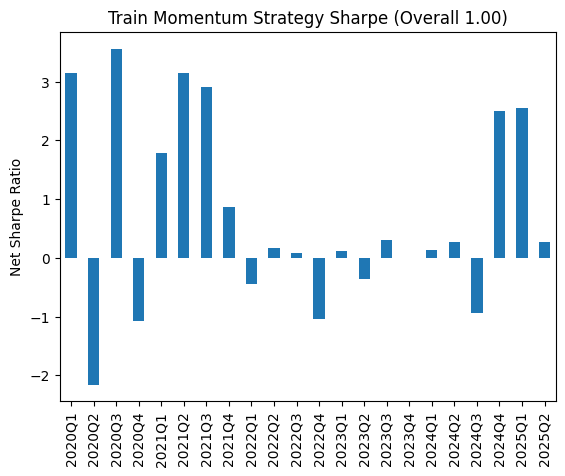

In [86]:
train_net_momentum.resample("QE").apply(sharpeRatio).to_period("Q").plot(kind="bar", title=f"Train Momentum Strategy Sharpe (Overall {sharpeRatio(train_net_momentum):.2f})", ylabel="Net Sharpe Ratio")

<Axes: title={'center': 'Mean Quarterly Turnover (Overall 0.00031)'}, ylabel='Turnover'>

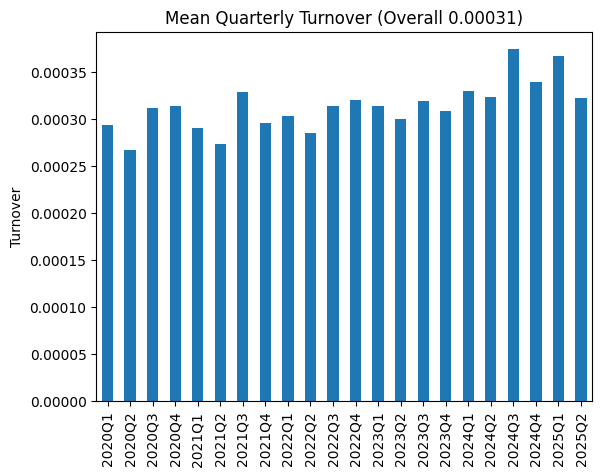

In [87]:
train_turnover.resample("QE").mean().to_period("Q").plot(kind="bar", title=f"Mean Quarterly Turnover (Overall {train_turnover.mean():.2})", ylabel="Turnover")

<Axes: title={'center': 'Train Momentum Drawdown'}, ylabel='Drawdown'>

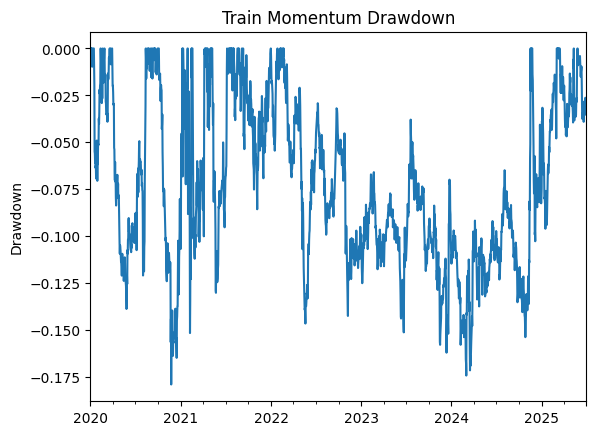

In [88]:
train_drawdown.plot(title="Train Momentum Drawdown", ylabel="Drawdown")

In [89]:
f"Strategy correlation with BTC-USD: {train_net_momentum.corr(daily_returns["BTC-USD"]):.3}"

'Strategy correlation with BTC-USD: 0.0372'

In [90]:
print(f"""
Training Alpha: {alpha(train_net_momentum)["alpha"]:.3}
Training Alpha T-Stat: {alpha(train_net_momentum)["t-stat"]:.3}
""")


Training Alpha: 0.00083
Training Alpha T-Stat: 2.73



## Test Sample Results

In [91]:
print(f"""
Testing Sample:
Gross Sharpe Ratio: {sharpeRatio(test_gross_momentum):.2f}
Net Sharpe Ratio: {sharpeRatio(test_net_momentum):.2f}
""")


Testing Sample:
Gross Sharpe Ratio: 0.37
Net Sharpe Ratio: -0.12



<Axes: title={'center': 'Test Momentum Strategy Sharpe (Overall -0.12)'}, ylabel='Net Sharpe Ratio'>

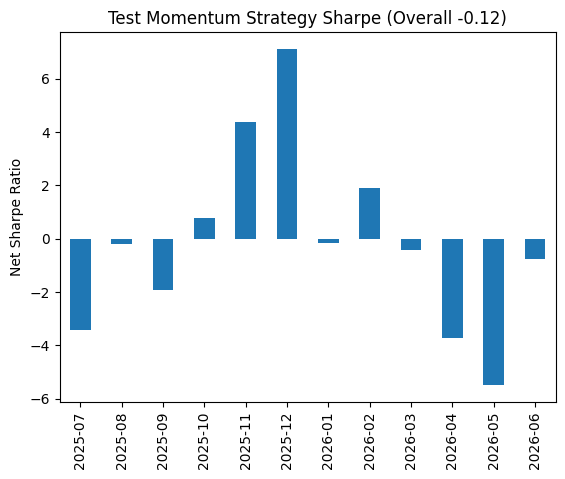

In [92]:
test_net_momentum.resample("ME").apply(sharpeRatio).to_period("M").plot(kind="bar", title=f"Test Momentum Strategy Sharpe (Overall {sharpeRatio(test_net_momentum):.2f})", ylabel="Net Sharpe Ratio")

<Axes: title={'center': 'Mean Monthly Turnover (Overall 0.00033)'}, ylabel='Turnover'>

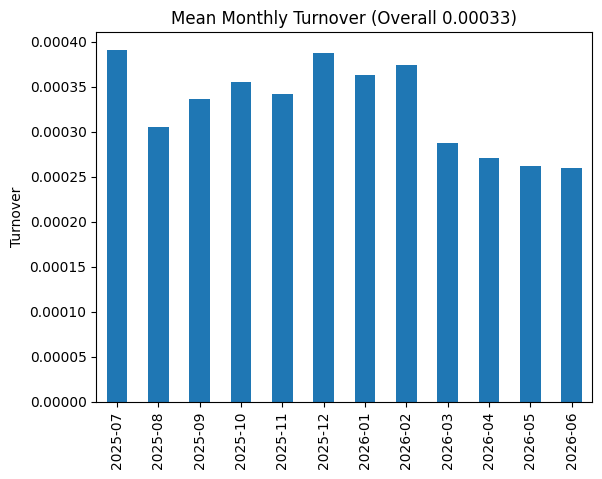

In [97]:
test_turnover.resample("ME").mean().to_period("M").plot(kind="bar", title=f"Mean Monthly Turnover (Overall {test_turnover.mean():.2})", ylabel="Turnover")

<Axes: title={'center': 'Train Momentum Drawdown'}, ylabel='Drawdown'>

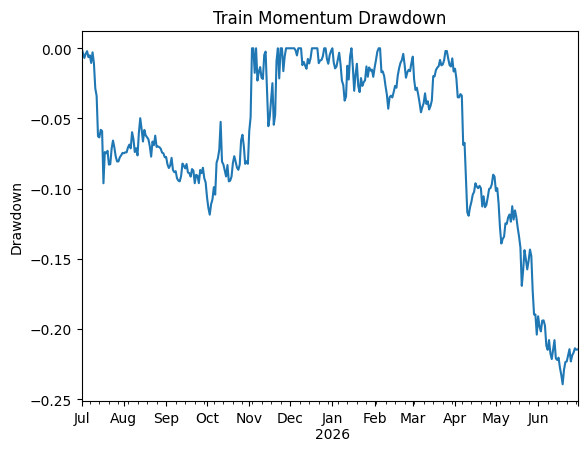

In [94]:
test_drawdown.plot(title="Train Momentum Drawdown", ylabel="Drawdown")

In [95]:
f"Strategy correlation with BTC-USD: {test_net_momentum.corr(daily_returns["BTC-USD"]):.3}"

'Strategy correlation with BTC-USD: -0.125'

In [96]:
print(f"""
Test Alpha: {alpha(test_net_momentum)["alpha"]:.3}
Test Alpha T-Stat: {alpha(test_net_momentum)["t-stat"]:.3}
""")


Test Alpha: -0.000159
Test Alpha T-Stat: -0.288



<Axes: xlabel='Date'>

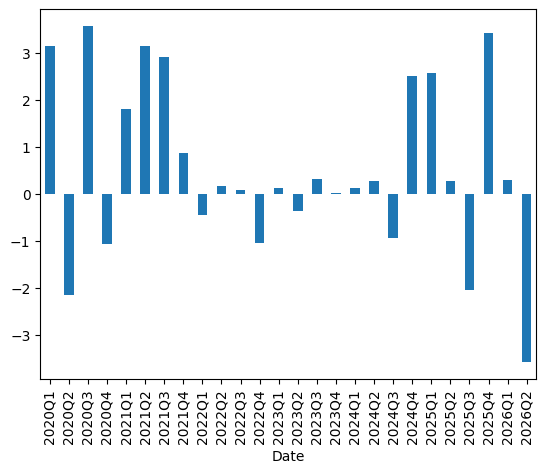

In [106]:
(momentum_weights * daily_returns).subtract((momentum_weights - momentum_weights.shift()).abs() * 0.002, fill_value=0).sum(axis=1)["2020-01-01":"2026-06-30"].resample("QE").apply(sharpeRatio).to_period("Q").plot(kind="bar")